In [35]:
import os
import torch
import shutil
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import mark_inset
from mpl_toolkits.axes_grid1.inset_locator import zoomed_inset_axes

from LMCE.models import MLP
from LMCE.utils import min_max
from LMCE.trainers import train
from LMCE.residual_calculation import indi_residuals
from LMCE.data_prep import prepare_data, create_dataloader
from LMCE.model_to_c_conversion import exportNet, nn_c_model_test

plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times']

In [38]:
residual_func = lambda data: indi_residuals(data, make_smooth=False, verbose=0, spline_segments=200)
kappas = np.array([
    2.0938753372837369e-10,
    2.2766702598220073e-10,
    1.906494181367591e-10,
    2.4578364131636854e-10
])

X_train, y_train_ = prepare_data(["./kms_clean/00.npy"],
                                 save_as="kms",
                                 residual_func=residual_func,
                                 shuffle_data=False,
                                 overwrite=True,
                                 payload=False,
                                 kappas=kappas,
                                 verbose=1)
print(X_train.shape)

100%|██████████| 1/1 [00:00<00:00, 28.65files/s]

(835, 19)


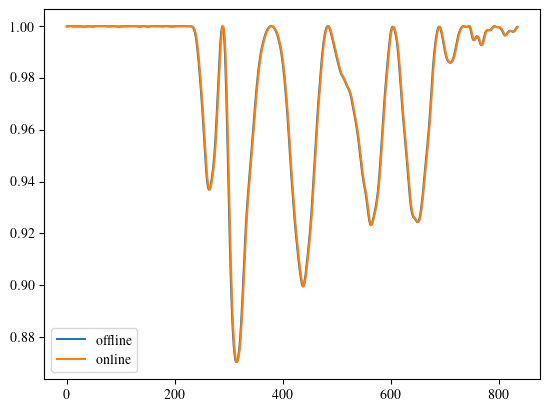

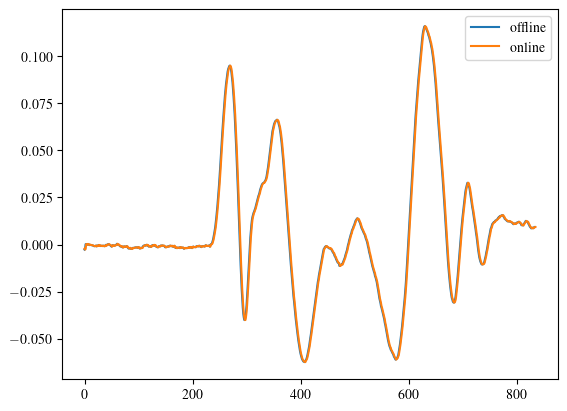

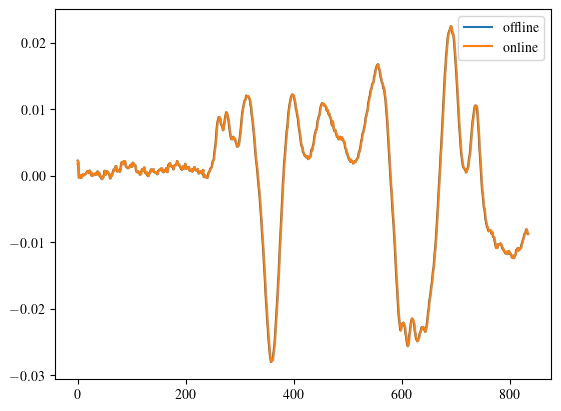

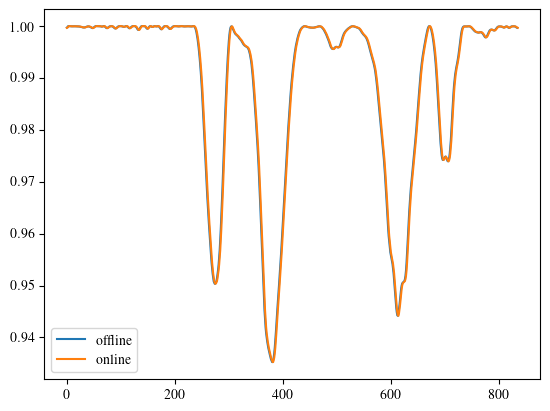

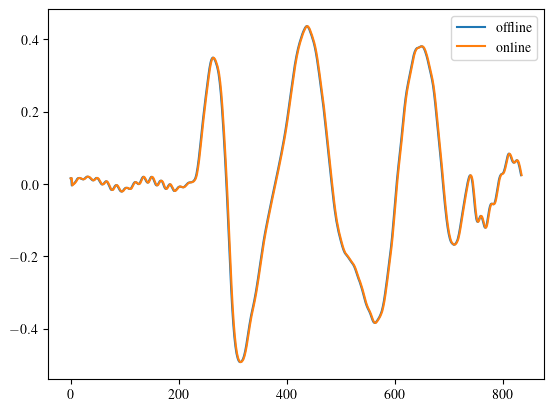

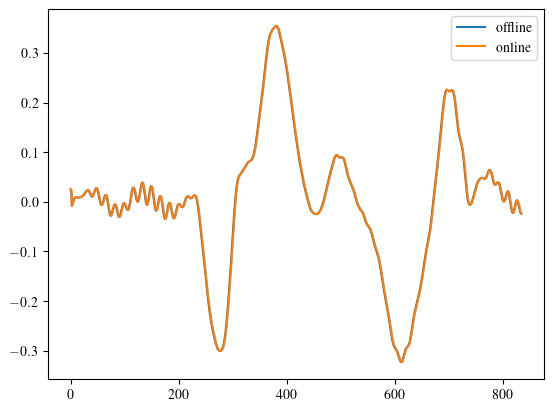

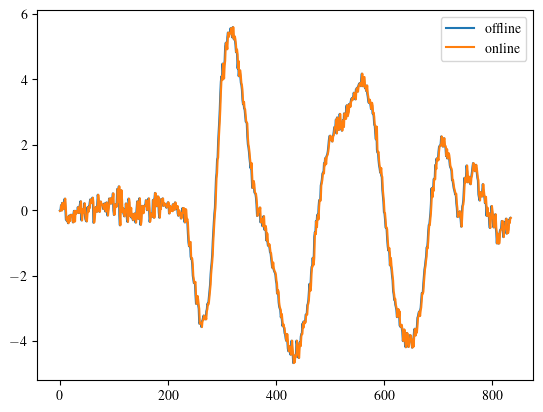

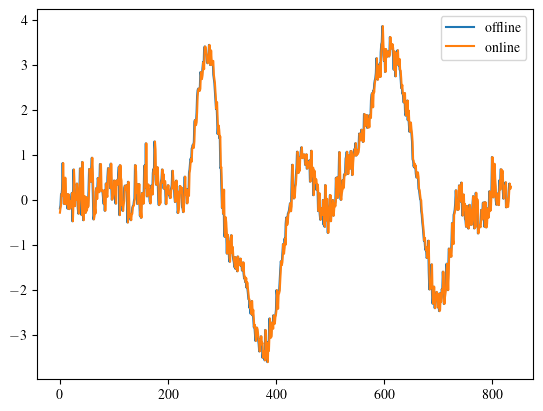

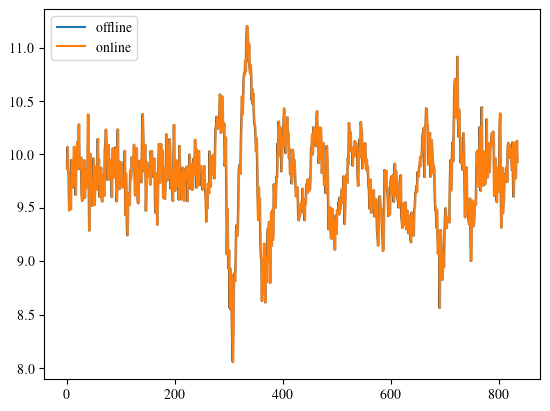

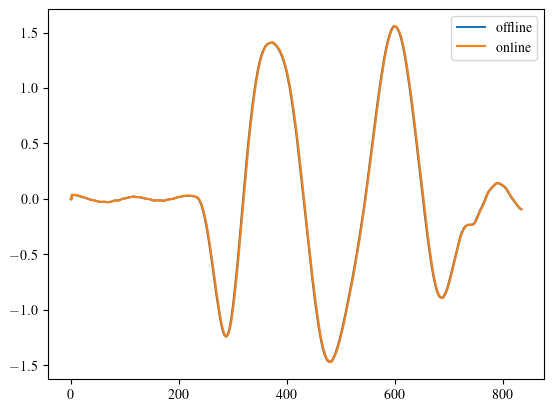

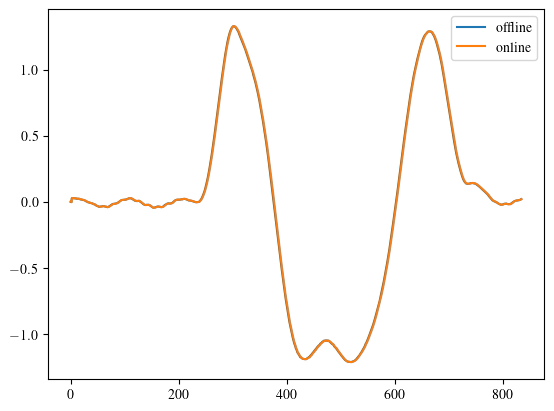

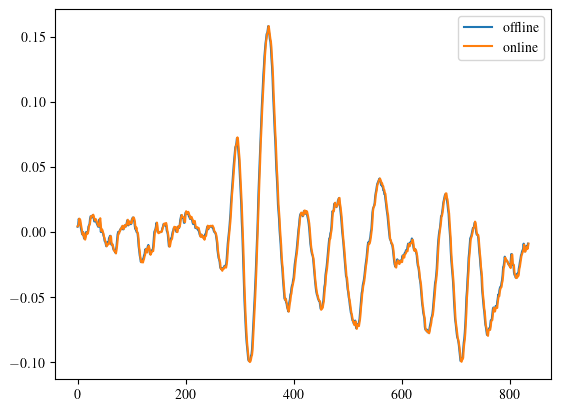

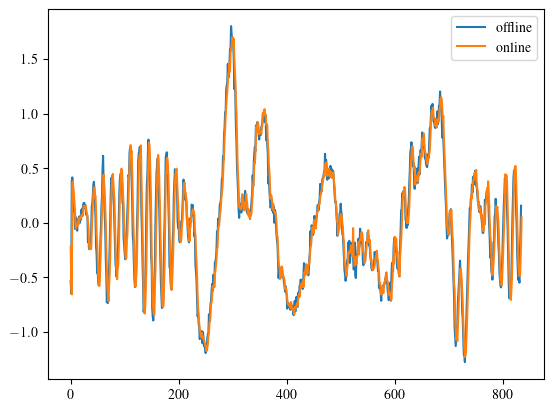

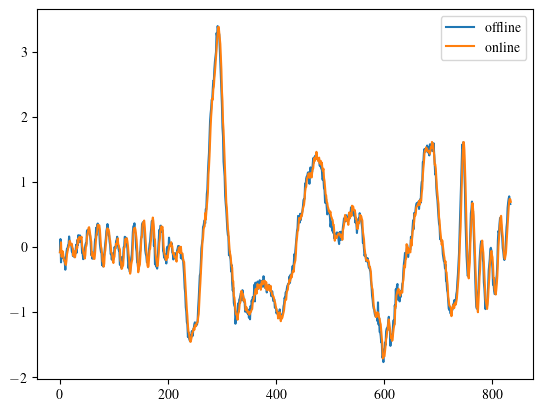

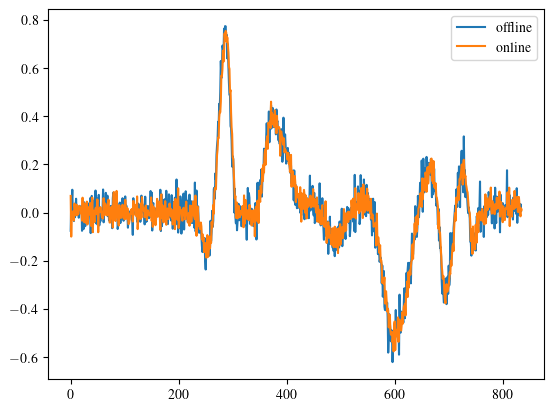

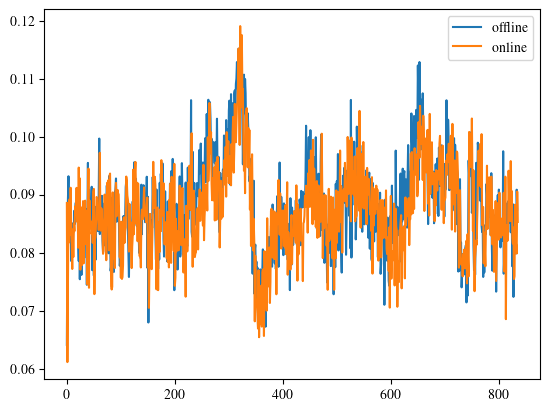

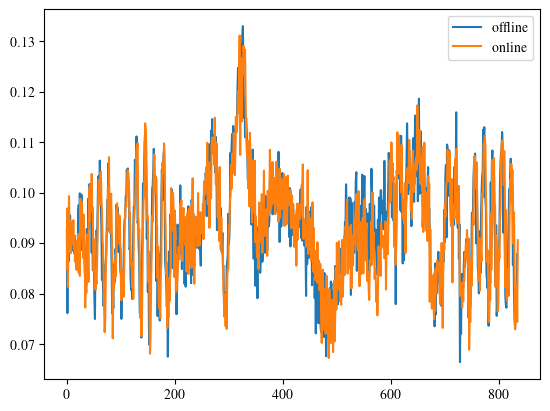

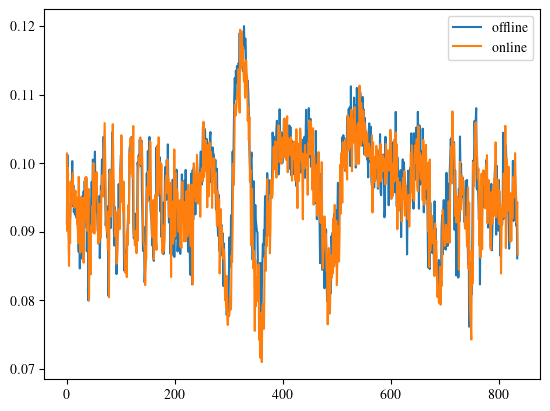

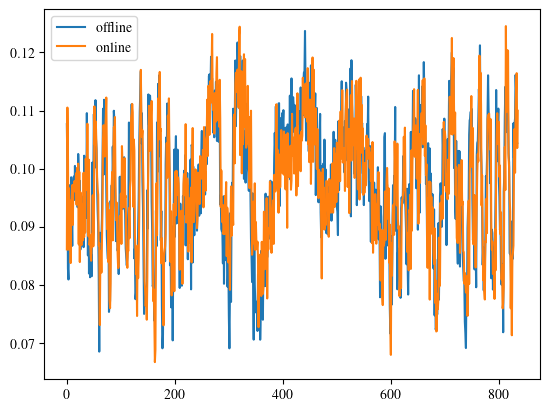

In [39]:
data_or = np.load("./kms_clean/00.npy", allow_pickle=True).item()

for i in range(19):
    plt.plot(X_train[:, i], label="offline")
    plt.plot(data_or[f"nn_input.i{i}"], label="online")
    plt.legend()
    plt.show()